# Semester Project

**Evan Morris**  
CS 625, Spring 2026  
Due: Sunday, May 3, 2026

In [2]:
import pandas as pd
import numpy as np
import scipy.spatial.distance as dist
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# google collab mounting
from google.colab import drive
drive.mount('/content/drive')

!pip install pyfonts
from pyfonts import load_google_font, set_default_font

Mounted at /content/drive


## Datasets

In [63]:
sdc_df = pd.read_csv('/content/drive/My Drive/district.csv').set_index('OBJECTID')
sdc_df.head()

,SURVYEAR,STATENAME,LEAID,ST_LEAID,LEA_NAME,LSTREET1,LSTREET2,LCITY,LSTATE,LZIP,...,TOTTCH,STUTERATIO,LOCALE_TEXT,CONAME,COID,PHONE,Lat,Long,Shape__Area,Shape__Length
OBJECTID,,,,,,,,,,,,,,,,,,,,,
1,2022-2023,FLORIDA,1200180,FL-06,Broward County School District,600 SE 3RD AVE FL 10,NaN,FORT LAUDERDALE,FL,33301,...,12532.89,20.33,21-Suburb: Large,Broward County,12011,(754)321-0000,26.114594,-80.139472,3.944242e+09,3.984587e+05
2,2022-2023,FLORIDA,1200240,FL-08,Charlotte County School District,1445 EDUCATION WAY,NaN,PORT CHARLOTTE,FL,33948,...,936.00,17.99,22-Suburb: Mid-size,Charlotte County,12015,(941)255-0808,27.005501,-82.145160,2.312790e+09,9.561971e+05
3,2022-2023,FLORIDA,1200330,FL-11,Collier County School District,5775 OSCEOLA TRL,NaN,NAPLES,FL,34109,...,2790.99,17.23,21-Suburb: Large,Collier County,12021,(239)377-0001,26.220768,-81.758198,6.577048e+09,1.347319e+06
4,2022-2023,FLORIDA,1200390,FL-13,Dade County School District,1450 NE 2ND AVE # 912,NaN,MIAMI,FL,33132,...,16606.00,20.12,21-Suburb: Large,Miami-Dade County,12086,(305)995-1000,25.788930,-80.190942,6.348318e+09,9.861156e+05
5,2022-2023,FLORIDA,1200420,FL-14,DeSoto County School District,530 LASOLONA AVE,NaN,ARCADIA,FL,34266,...,241.00,19.01,32-Town: Distant,DeSoto County,12027,(863)494-4222,27.221257,-81.848946,2.100186e+09,1.871353e+05


In [64]:
ipr_df = pd.read_csv('/content/drive/My Drive/ipr.csv').set_index('OBJECTID')
ipr_df.head()

,School ID,Name,IPR_EST,IPR_SE,LAT,LON,LEAID,School Year,x,y
OBJECTID,,,,,,,,,,
1,10000500870,Albertville Middle School,206,42,34.2602,-86.206200,100005,2021-2022,-86.206200,34.2602
2,10000500871,Albertville High School,201,43,34.2622,-86.204900,100005,2021-2022,-86.204900,34.2622
3,10000500879,Albertville Intermediate School,164,43,34.2733,-86.220100,100005,2021-2022,-86.220100,34.2733
4,10000500889,Albertville Elementary School,225,54,34.2527,-86.221806,100005,2021-2022,-86.221806,34.2527
5,10000501616,Albertville Kindergarten and PreK,278,93,34.2898,-86.193300,100005,2021-2022,-86.193300,34.2898


## Data Cleaning

In [65]:
# dropped NaN values by column
sdc_df_filtered = sdc_df.dropna(axis=1)

# filtering rows with incomplete data
# dropping rows with incomplete data
bad_data_values = [-1, -2, -9]
bad_data_rows = sdc_df_filtered.isin(bad_data_values).any(axis=1)
sdc_df_filtered = sdc_df_filtered.drop(sdc_df_filtered.loc[bad_data_rows].index)

# filtering important attributes to a new dataframes
# formatting locale text
district_df = sdc_df_filtered.loc[:,['LEA_NAME', 'STATENAME', 'SCH', 'MEMBER', 'TOTTCH', 'STUTERATIO', 'LOCALE_TEXT', 'Long', 'Lat']]
district_df = district_df.rename(columns={'Long': 'x'})
district_df = district_df.rename(columns={'Lat': 'y'})
district_df['LOCALE_TEXT'] = district_df['LOCALE_TEXT'].str.replace(r"^\d{2}-", "", regex=True)

# district dataframe clean
district_df.head()

,LEA_NAME,STATENAME,SCH,MEMBER,TOTTCH,STUTERATIO,LOCALE_TEXT,x,y
OBJECTID,,,,,,,,,
1,Broward County School District,FLORIDA,329,254732,12532.89,20.33,Suburb: Large,-80.139472,26.114594
2,Charlotte County School District,FLORIDA,25,16834,936.00,17.99,Suburb: Mid-size,-82.145160,27.005501
3,Collier County School District,FLORIDA,73,48082,2790.99,17.23,Suburb: Large,-81.758198,26.220768
4,Dade County School District,FLORIDA,542,334090,16606.00,20.12,Suburb: Large,-80.190942,25.788930
5,DeSoto County School District,FLORIDA,11,4582,241.00,19.01,Town: Distant,-81.848946,27.221257


In [66]:
# verify is NaN values within the DataFrame
ipr_df.loc[ipr_df.isna().any(axis=1)]

,School ID,Name,IPR_EST,IPR_SE,LAT,LON,LEAID,School Year,x,y
OBJECTID,,,,,,,,,,


In [67]:
# verify the upper and lower bound of IPR_EST
ipr_df.loc[~((ipr_df['IPR_EST'] < 1000) & (ipr_df['IPR_EST'] >= 0))]

,School ID,Name,IPR_EST,IPR_SE,LAT,LON,LEAID,School Year,x,y
OBJECTID,,,,,,,,,,


In [68]:
# ipr dataframe clean
schools_df = ipr_df.loc[:, ['Name', 'IPR_EST', 'x', 'y']]
schools_df.head()

,Name,IPR_EST,x,y
OBJECTID,,,,
1,Albertville Middle School,206,-86.206200,34.2602
2,Albertville High School,201,-86.204900,34.2622
3,Albertville Intermediate School,164,-86.220100,34.2733
4,Albertville Elementary School,225,-86.221806,34.2527
5,Albertville Kindergarten and PreK,278,-86.193300,34.2898


## K Nearest Neighbor Machine Learning for Districting

In [69]:
# finding the district distance and creating a distance vector
xy_coord_district = district_df[['x', 'y']].values
xy_coord_schools = schools_df[['x', 'y']].values

dist_matrix = dist.cdist(xy_coord_schools, xy_coord_district, metric='euclidean')


In [70]:
#finding the nears district and creating the two new columns
nearest_idx = np.argmin(dist_matrix, axis=1)

schools_df['Distance'] = dist_matrix[np.arange(len(schools_df)), nearest_idx]
schools_df['State'] = district_df.iloc[nearest_idx]['STATENAME'].values
schools_df['District'] = district_df.iloc[nearest_idx]['LEA_NAME'].values

schools_df.head()


,Name,IPR_EST,x,y,Distance,State,District
OBJECTID,,,,,,,
1,Albertville Middle School,206,-86.206200,34.2602,0.028055,ALABAMA,Albertville City School District
2,Albertville High School,201,-86.204900,34.2622,0.027389,ALABAMA,Albertville City School District
3,Albertville Intermediate School,164,-86.220100,34.2733,0.009560,ALABAMA,Albertville City School District
4,Albertville Elementary School,225,-86.221806,34.2527,0.029542,ALABAMA,Albertville City School District
5,Albertville Kindergarten and PreK,278,-86.193300,34.2898,0.031268,ALABAMA,Albertville City School District


In [71]:
avg_df = schools_df.groupby('District')['IPR_EST'].mean()
district_df['IPR_AVG'] = round(district_df['LEA_NAME'].map(avg_df), 2)
district_df= district_df.dropna(axis=0)
district_df.head()



,LEA_NAME,STATENAME,SCH,MEMBER,TOTTCH,STUTERATIO,LOCALE_TEXT,x,y,IPR_AVG
OBJECTID,,,,,,,,,,
1,Broward County School District,FLORIDA,329,254732,12532.89,20.33,Suburb: Large,-80.139472,26.114594,307.19
2,Charlotte County School District,FLORIDA,25,16834,936.00,17.99,Suburb: Mid-size,-82.145160,27.005501,247.62
3,Collier County School District,FLORIDA,73,48082,2790.99,17.23,Suburb: Large,-81.758198,26.220768,322.88
4,Dade County School District,FLORIDA,542,334090,16606.00,20.12,Suburb: Large,-80.190942,25.788930,266.02
5,DeSoto County School District,FLORIDA,11,4582,241.00,19.01,Town: Distant,-81.848946,27.221257,250.71


In [72]:
# data exploration: members to school ratio, and techers to school ratio
district_df['MEMTOSCH'] = round(district_df['MEMBER'] / district_df['SCH'], 2)
district_df['TCHTOSCH'] = round(district_df['TOTTCH'] / district_df['SCH'], 2)
district_df.head()

,LEA_NAME,STATENAME,SCH,MEMBER,TOTTCH,STUTERATIO,LOCALE_TEXT,x,y,IPR_AVG,MEMTOSCH,TCHTOSCH
OBJECTID,,,,,,,,,,,,
1,Broward County School District,FLORIDA,329,254732,12532.89,20.33,Suburb: Large,-80.139472,26.114594,307.19,774.26,38.09
2,Charlotte County School District,FLORIDA,25,16834,936.00,17.99,Suburb: Mid-size,-82.145160,27.005501,247.62,673.36,37.44
3,Collier County School District,FLORIDA,73,48082,2790.99,17.23,Suburb: Large,-81.758198,26.220768,322.88,658.66,38.23
4,Dade County School District,FLORIDA,542,334090,16606.00,20.12,Suburb: Large,-80.190942,25.788930,266.02,616.40,30.64
5,DeSoto County School District,FLORIDA,11,4582,241.00,19.01,Town: Distant,-81.848946,27.221257,250.71,416.55,21.91


In [73]:
# there is one reported district with no schools
# dropping district with 0 schools
district_df = district_df.drop(district_df[district_df['SCH'] == 0].index)

In [74]:
# writing nearest neighbor data to CSV for easier access
district_df.to_csv('/content/drive/My Drive/cleaned_data.csv')

## Data Visualization

In [217]:
clean_df = pd.read_csv('/content/drive/My Drive/cleaned_data.csv').set_index('OBJECTID')

# filtering virginia districts
va_df = (clean_df.loc[clean_df['STATENAME'] == 'VIRGINIA']
         .loc[:,['LEA_NAME','STATENAME', 'LOCALE_TEXT','IPR_AVG', 'STUTERATIO', 'MEMTOSCH', 'MEMBER']]
         .copy()
         .rename(columns={'LEA_NAME':'District Name',
                          'STATENAME':'State',
                          'STUTERATIO':'Student to Teacher (Avg)',
                          'LOCALE_TEXT':'Area Classification',
                          'IPR_AVG':'Income to Poverty (Avg)',
                          'MEMTOSCH':'Student to School (Avg)',})

        )
va_df['Area Classification'] = va_df['Area Classification'].str.replace(r':.*', '', regex=True)
va_df.head()

,District Name,State,Area Classification,Income to Poverty (Avg),Student to Teacher (Avg),Student to School (Avg),MEMBER
OBJECTID,,,,,,,
6403,Lexington City Public Schools,VIRGINIA,Town,315.17,11.90,242.50,485
12447,Accomack County Public Schools,VIRGINIA,Rural,296.09,12.50,363.54,4726
12448,Albemarle County Public Schools,VIRGINIA,Rural,440.28,12.86,557.48,13937
12449,Alexandria City Public Schools,VIRGINIA,City,476.35,13.78,844.21,16040
12450,Alleghany Highlands Public Schools,VIRGINIA,Rural,292.55,12.60,359.75,2878


In [218]:
va_df[va_df['Student to Teacher (Avg)'] > 25]

,District Name,State,Area Classification,Income to Poverty (Avg),Student to Teacher (Avg),Student to School (Avg),MEMBER
OBJECTID,,,,,,,
12545,Radford City Public Schools,VIRGINIA,Suburb,309.3,31.4,738.0,3690


In [230]:
va_df[va_df['Income to Poverty (Avg)'] > 650]

,District Name,State,Area Classification,Income to Poverty (Avg),Student to Teacher (Avg),Student to School (Avg),MEMBER
OBJECTID,,,,,,,
12454,Arlington County Public Schools,VIRGINIA,City,701.30,11.57,656.24,27562
12483,Fairfax County Public Schools,VIRGINIA,Suburb,662.41,14.19,806.54,179858
12484,Falls Church City Public Schools,VIRGINIA,Suburb,680.02,12.04,499.20,2496
12513,Loudoun County Public Schools,VIRGINIA,Suburb,701.29,12.54,825.03,81678


In [281]:
va_df.shape

(131, 7)

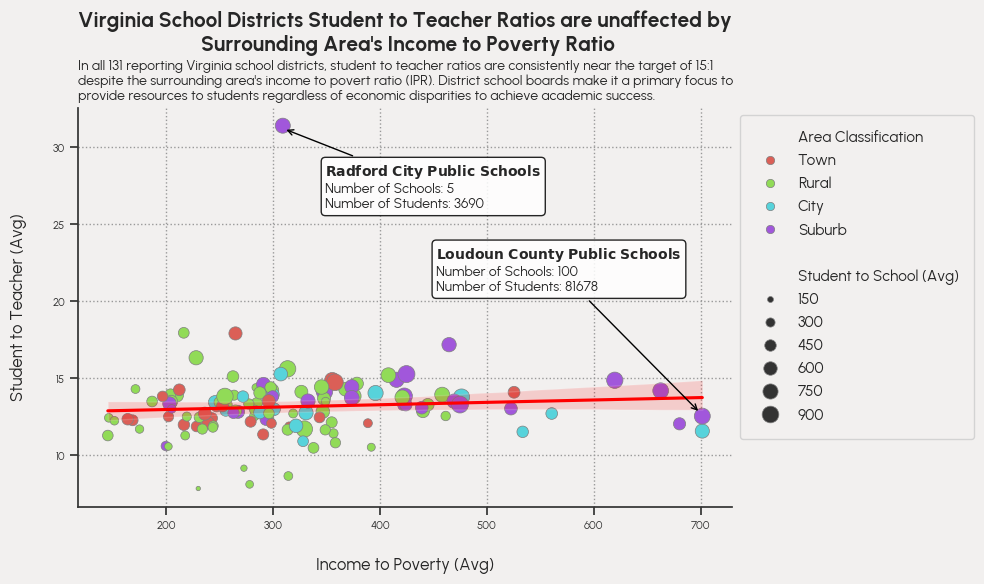

In [335]:
# theme settings
font = load_google_font('Urbanist')
set_default_font(font)
rc = {'axes.spines.left': True,
                 'axes.facecolor': "#F2F0EF",
                 'axes.spines.bottom': True,
                 'axes.spines.top': False,
                 'axes.spines.right': False,
                 'axes.edgecolor': '.2',
                 'figure.facecolor': '#F2F0EF',
                 'font.family': font.get_name(),
                 'grid.color': '.6',
                 'grid.linestyle': ':',
                 'xtick.bottom': True,
                 'xtick.color': '.2',
                 'ytick.left': True,
                 'ytick.color': '.2'}

sns.set_theme(style='darkgrid', rc=rc)

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=va_df,
    x='Income to Poverty (Avg)',
    y='Student to Teacher (Avg)',
    size= 'Student to School (Avg)',
    sizes=(10, 150),
    hue='Area Classification',
    palette='hls',
    edgecolor='grey'
)

sns.regplot(
    data=va_df,
    x='Income to Poverty (Avg)',
    y='Student to Teacher (Avg)',
    scatter=False,
    ax=ax,
    ci=95,
    color='.2',
    line_kws=dict(color='red')
)

# text annotations
ax.annotate(
    r'$\mathbf{Radford\ City\ Public\ Schools}$'
    '\nNumber of Schools: 5'
    '\nNumber of Students: 3690',
    xy=(310.2, 31.2),
    xytext=(30, -25),
    textcoords='offset points',
    ha='left',
    va='top',
    fontsize=10,
    arrowprops=dict(
        arrowstyle='->',
        color='black',
        lw=1
    ),
    bbox=dict(
        boxstyle='round,pad=0.3',
        facecolor='white',
        edgecolor='black',
        alpha=0.85
    )
)

ax.annotate(
    r'$\mathbf{Loudoun\ County\ Public\ Schools}$'
    '\nNumber of Schools: 100'
    '\nNumber of Students: 81678',
    xy=(699.29, 12.75),
    xytext=(-190,120),
    textcoords='offset points',
    ha='left',
    va='top',
    fontsize=10,
    arrowprops=dict(
        arrowstyle='->',
        color='black',
        lw=1
    ),
    bbox=dict(
        boxstyle='round,pad=0.3',
        facecolor='white',
        edgecolor='black',
        alpha=0.85
    )
)

# legend settings
handles, labels = ax.get_legend_handles_labels()
n = va_df['Area Classification'].nunique()
handles.insert(n+1, plt.Line2D([], [], linestyle=''))
labels.insert(n+1, '')
legend = ax.legend(
    handles,
    labels,
    loc='upper left',
    bbox_to_anchor=(1, 1),
    borderpad=1,
    labelspacing=.5,
)

# matplotlib settings
plt.xlabel('\nIncome to Poverty (Avg)', fontsize=12)
plt.ylabel('Student to Teacher (Avg)\n', fontsize=12)
plt.xticks(ticks=(np.arange(200,800,100)), fontsize=8)
plt.yticks(fontsize=8)

# headline
plt.title('Virginia School Districts Student to Teacher Ratios are unaffected by\n Surrounding Area\'s Income to Poverty Ratio\n\n', fontsize=15, fontweight='bold')
ax.text(
    0.0, 1.12,
    'In all 131 reporting Virginia school districts, student to teacher ratios are consistently near the target of 15:1\n'
    'despite the surrounding area\'s income to povert ratio (IPR). District school boards make it a primary focus to\n'
    'provide resources to students regardless of economic disparities to achieve academic success.',
    transform=ax.transAxes,
    ha='left',
    va='top',
    fontsize=10
)


plt.tight_layout()
plt.show()